# HUMIR Domain Identification: Keyword vs. ML vs. Original Labels

**Objective:** Compare three ways of separating HUMIR reviews into Movie and Hotel domains:

- **Approach A – Keyword-based:** the existing keyword rules (substring matching, hotel words checked first).
- **Approach B – Machine learning:** a TF-IDF + Logistic Regression domain classifier trained on the original Type labels.
- **Approach C – Original labels:** the HUMIR `Type` field (reference / ground truth).

A and B are evaluated against C with accuracy, Macro-F1 and confusion matrices. For A, misclassified and unclassified reviews are reported separately.

**Input:** `data/humir_domain_labels_AC.csv` (text, label, domain_C, domain_A)
**Output:** `data/humir_domain_labels_ABC.csv` (adds domain_B) and tables/figures in `reports/humir_domain_identification/`

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
DATA_DIR = "../data"
OUT_DIR = "../reports/humir_domain_identification"
os.makedirs(OUT_DIR, exist_ok=True)

DOMAINS = ["Movie Reviews", "Hotel Reviews"]
HOTEL_WORDS = ["otel", "oda", "personel", "kahvaltı", "resepsiyon", "konaklama", "tesis", "tatil", "temiz"]
MOVIE_WORDS = ["film", "sinema", "sahne", "oyuncu", "yönetmen", "senaryo", "kurgu", "vizyon", "karakter"]

## 1. Load data

In [2]:
df = pd.read_csv(f"{DATA_DIR}/humir_domain_labels_AC.csv")
print(df.shape)
print("duplicate texts:", df["text"].duplicated().sum())

print("\nApproach C (original Type):")
print(df["domain_C"].value_counts(dropna=False))
print("\nApproach A (keyword):")
print(df["domain_A"].value_counts(dropna=False))

# reviews without an original Type label cannot be used as reference
n_unmatched = df["domain_C"].isna().sum()
print(f"\nReviews without an original Type label (excluded from evaluation): {n_unmatched}")
ref = df[df["domain_C"].notna()].reset_index(drop=True)
print("Reviews used for evaluation:", len(ref))

(64454, 4)
duplicate texts: 0

Approach C (original Type):
domain_C
Movie Reviews    53230
Hotel Reviews    11162
NaN                 62
Name: count, dtype: int64

Approach A (keyword):
domain_A
Movie Reviews    44800
Hotel Reviews    10953
Unclassified      8701
Name: count, dtype: int64

Reviews without an original Type label (excluded from evaluation): 62
Reviews used for evaluation: 64392


## 2. Approach A – Keyword-based vs. original labels

The keyword method also produces **Unclassified** reviews (no keyword found). They are reported in two ways:
- **Coverage:** share of reviews that receive a domain at all.
- **Strict evaluation:** all reviews, with Unclassified counted as an error.
- **Classified-only evaluation:** only the reviews that received a domain.

In [3]:
def evaluate(y_true, y_pred, name):
    return {"approach": name, "n": len(y_true),
            "accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, labels=DOMAINS, average="macro")}

classified = ref["domain_A"] != "Unclassified"
coverage = classified.mean()
print(f"Coverage: {coverage:.2%} ({classified.sum()} of {len(ref)} reviews classified, {(~classified).sum()} unclassified)\n")

res_A_strict = evaluate(ref["domain_C"], ref["domain_A"], "A – keyword (strict, Unclassified = error)")
res_A_cls = evaluate(ref.loc[classified, "domain_C"], ref.loc[classified, "domain_A"], "A – keyword (classified only)")
print(pd.DataFrame([res_A_strict, res_A_cls]).round(4).to_string(index=False))

print("\nConfusion matrix (rows = original label, columns = keyword label):")
cm_A = pd.crosstab(ref["domain_C"], ref["domain_A"], margins=True)
print(cm_A)
cm_A.to_csv(f"{OUT_DIR}/confusion_A_keyword.csv")

print("\nClassification report (classified only):")
print(classification_report(ref.loc[classified, "domain_C"], ref.loc[classified, "domain_A"], digits=4))

Coverage: 86.58% (55753 of 64392 reviews classified, 8639 unclassified)



                                  approach     n  accuracy  macro_f1
A – keyword (strict, Unclassified = error) 64392    0.8448    0.8912
             A – keyword (classified only) 55753    0.9757    0.9597

Confusion matrix (rows = original label, columns = keyword label):
domain_A       Hotel Reviews  Movie Reviews  Unclassified    All
domain_C                                                        
Hotel Reviews           9603              3          1556  11162
Movie Reviews           1350          44797          7083  53230
All                    10953          44800          8639  64392

Classification report (classified only):


               precision    recall  f1-score   support

Hotel Reviews     0.8767    0.9997    0.9342      9606
Movie Reviews     0.9999    0.9707    0.9851     46147

     accuracy                         0.9757     55753
    macro avg     0.9383    0.9852    0.9597     55753
 weighted avg     0.9787    0.9757    0.9763     55753



### 2.1 Keyword errors in detail
Which keyword caused each error, and examples of misclassified and unclassified reviews.

In [4]:
def hit_words(text, words):
    t = str(text).lower()
    return [w for w in words if w in t]

err_A = ref[classified & (ref["domain_A"] != ref["domain_C"])].copy()
err_A["hotel_words_found"] = err_A["text"].apply(lambda t: hit_words(t, HOTEL_WORDS))
err_A["movie_words_found"] = err_A["text"].apply(lambda t: hit_words(t, MOVIE_WORDS))

print("Misclassified by keyword:", len(err_A))
print(pd.crosstab(err_A["domain_C"], err_A["domain_A"]).rename_axis(index="original", columns="keyword"))

m2h = err_A[(err_A["domain_C"] == "Movie Reviews") & (err_A["domain_A"] == "Hotel Reviews")]
print(f"\nMovie -> Hotel errors: {len(m2h)}. Hotel keywords that triggered them:")
print(pd.Series([w for ws in m2h["hotel_words_found"] for w in ws]).value_counts())

unc_A = ref[~classified].copy()
print(f"\nUnclassified by keyword: {len(unc_A)}")
print(unc_A["domain_C"].value_counts().rename("original label"))

err_A[["text", "label", "domain_C", "domain_A", "hotel_words_found", "movie_words_found"]].to_csv(
    f"{OUT_DIR}/keyword_misclassified.csv", index=False)
unc_A[["text", "label", "domain_C"]].to_csv(f"{OUT_DIR}/keyword_unclassified.csv", index=False)

pd.set_option("display.max_colwidth", 140)
print("\nExamples – misclassified (Movie -> Hotel):")
display(m2h[["text", "hotel_words_found"]].sample(min(8, len(m2h)), random_state=SEED))
h2m = err_A[(err_A["domain_C"] == "Hotel Reviews") & (err_A["domain_A"] == "Movie Reviews")]
if len(h2m):
    print("Examples – misclassified (Hotel -> Movie):")
    display(h2m[["text", "movie_words_found"]].sample(min(8, len(h2m)), random_state=SEED))
print("Examples – unclassified:")
display(unc_A[["text", "domain_C"]].sample(min(8, len(unc_A)), random_state=SEED))

Misclassified by keyword: 1353
keyword        Hotel Reviews  Movie Reviews
original                                   
Hotel Reviews              0              3
Movie Reviews           1350              0

Movie -> Hotel errors: 1350. Hotel keywords that triggered them:
oda         1132
temiz         92
otel          77
tatil         56
kahvaltı      11
tesis          6
personel       1
Name: count, dtype: int64

Unclassified by keyword: 8639
domain_C
Movie Reviews    7083
Hotel Reviews    1556
Name: original label, dtype: int64

Examples – misclassified (Movie -> Hotel):


,text,hotel_words_found
14188,"Bir sürü 'en'lerin ödülünü toplayan bu film, allahtan en iyi senaryo ödülünü almamış. Yoksa Türk sinemasına inancım hiç kalmayacaktı. A...",[oda]
49497,bizimkilerin daha 40 fırın ekmek yemesi lazım. para verip gittiginde kaliteli bişey bekliyorsun senaryoda ve görsellikte kaybolmak. ama...,[oda]
25948,DAVİD.S GOYER BATIRDIN YAVRUCUM BENİM EN SEVDİĞİM ÇİZGİ ROMAN KAHRAMANININ KARİZMASINI PASPAS ETTİN.BİRİNCİ BİR BAŞYAPITTI ONA LAF YOK....,[oda]
16778,Dersu dünyadaki en saf ve en temiz kalpli insan. Bu nasil bir ustaliktir böyle yönetmenler gerçekten dünyaya bir daha gelmez. Dogayla o...,[temiz]
51352,film öncelikle ilk yapılan ve ikinci yapılanla aynı mantıkta tamamen seyirci odaklı bir film yinede güzel bir film tabi ama başyapıt bi...,[oda]
37141,Film fantastik film başlığı altında bi çok şey içeriyor. Yaşadığı dönem ve olaylar sonucu kendi hayal dünyasını kuran küçük bir kızın e...,[oda]
14930,Klasik festival filmi :) Bu filmden sonra festival ödüllü filmlere olan ön yargım daha bir perçinlendi. Reçete belli: ağırdan ilerleyen...,[oda]
35826,bu kadar iyi kadrodan bu kadar kötü flim nasıl cıkmış hayreeet,[oda]


Examples – misclassified (Hotel -> Movie):


,text,movie_words_found
17588,çok sıkıcıöğlenleri yemek verilen restoranın yemekleri çok kötü ve çok pahalı saat beklemek zorunda kalıyorsunuz akşamları korku filmin...,[film]
48469,berbatmerhababiz de gece için anlaştık ilk gece kalmamakta ısrar ettik ancak geç giriş yaptığımız ve ilk geceyi ödeyemeyeceklerini beli...,[film]
58876,Televizyon kanallarını seyredemiyoruz 5-6 kanal var başka birşey yok yemekleri güzel içecekleri kaliteliydi.,[vizyon]


Examples – unclassified:


,text,domain_C
52321,kesinlikle vakit kaybı! ayrıca çok saçmalamışlar.,Movie Reviews
32884,tam anlamıyla bir başyapıt,Movie Reviews
1516,fena değildi.izlerken sonunu az çok tahmin edebiliyorsunuz.içlerinden birinin olayı başlatması filan.bildiğimiz konular..ama josh hartn...,Movie Reviews
30649,İnsan ilişkilerinden çok iyiler. Garsonlar iyi. Çok memnun kaldık. Havuzdan animasyondan yemeklerden memnun kaldım. Bunlardan dolayı tav...,Hotel Reviews
2249,Val çok iyi.Aksiyonda döktürebileceğini ispatlıyor.Ayrıca Sue ilede acayip yakışmış yani.,Movie Reviews
41014,berbattttıııııııııııııııııı allahımmmm ona pislikti öyle fırsattan satın alıp gittik eşimle gitmez olaydım aklıma geldikçe hala midem...,Hotel Reviews
5326,mükemmel bi animasyonn..motorlar we kılıçlarr harikaa,Movie Reviews
59193,kocaman bi PÖFFFF!!,Movie Reviews


## 3. Approach B – TF-IDF + Logistic Regression domain classifier

**Evaluation (held-out split):** the classifier is trained on 80% of the reviews and evaluated on the remaining 20% (stratified by original domain, seed 42). It never sees the test reviews during training.

**Domain assignment for all reviews:** to give every review a B label without using a model that was trained on that same review, 5-fold cross-validated predictions are used: each review is labelled by the model trained on the other four folds.

In [5]:
def make_domain_clf():
    return make_pipeline(
        TfidfVectorizer(max_features=20000, ngram_range=(1, 2)),
        LogisticRegression(max_iter=1000, random_state=SEED))

X, y = ref["text"], ref["domain_C"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
print(f"train: {len(X_tr)} | test: {len(X_te)}")

clf_B = make_domain_clf().fit(X_tr, y_tr)
pred_te = clf_B.predict(X_te)

res_B = evaluate(y_te, pred_te, "B – TF-IDF + LR (held-out 20% test)")
print(pd.DataFrame([res_B]).round(4).to_string(index=False))
print("\nConfusion matrix (rows = original label, columns = ML label):")
cm_B = pd.crosstab(pd.Series(y_te.values, name="domain_C"), pd.Series(pred_te, name="domain_B"), margins=True)
print(cm_B)
cm_B.to_csv(f"{OUT_DIR}/confusion_B_ml_heldout.csv")
print("\nClassification report:")
print(classification_report(y_te, pred_te, digits=4))

train: 51513 | test: 12879


                           approach     n  accuracy  macro_f1
B – TF-IDF + LR (held-out 20% test) 12879    0.9884    0.9793

Confusion matrix (rows = original label, columns = ML label):
domain_B       Hotel Reviews  Movie Reviews    All
domain_C                                          
Hotel Reviews           2089            144   2233
Movie Reviews              5          10641  10646
All                     2094          10785  12879

Classification report:
               precision    recall  f1-score   support

Hotel Reviews     0.9976    0.9355    0.9656      2233
Movie Reviews     0.9866    0.9995    0.9930     10646

     accuracy                         0.9884     12879
    macro avg     0.9921    0.9675    0.9793     12879
 weighted avg     0.9885    0.9884    0.9883     12879



In [6]:
# 5-fold cross-validated domain assignment for every review
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
ref["domain_B"] = cross_val_predict(make_domain_clf(), X, y, cv=skf)

res_B_cv = evaluate(ref["domain_C"], ref["domain_B"], "B – TF-IDF + LR (5-fold CV, all reviews)")
print(pd.DataFrame([res_B_cv]).round(4).to_string(index=False))

err_B = ref[ref["domain_B"] != ref["domain_C"]]
print(f"\nMisclassified by ML (5-fold CV): {len(err_B)}")
print(pd.crosstab(err_B["domain_C"], err_B["domain_B"]).rename_axis(index="original", columns="ml"))
err_B[["text", "label", "domain_C", "domain_B"]].to_csv(f"{OUT_DIR}/ml_misclassified.csv", index=False)
print("\nExamples – misclassified by ML:")
display(err_B[["text", "domain_C", "domain_B"]].sample(min(8, len(err_B)), random_state=SEED))

                                approach     n  accuracy  macro_f1
B – TF-IDF + LR (5-fold CV, all reviews) 64392    0.9895    0.9813

Misclassified by ML (5-fold CV): 673
ml             Hotel Reviews  Movie Reviews
original                                   
Hotel Reviews              0            650
Movie Reviews             23              0

Examples – misclassified by ML:


,text,domain_C,domain_B
20265,Valla hıc bır kusur bulamadık şahane .,Hotel Reviews,Movie Reviews
30021,MANZARA HARİKA,Hotel Reviews,Movie Reviews
29422,Mükemmeldi.,Hotel Reviews,Movie Reviews
28931,sakin kardeslerim aldanmayin bu kadar rezillik bir arada görmedim verilen sözler havadan sudan islam ile bir alakasi yok paramizi hala b...,Hotel Reviews,Movie Reviews
59782,Levent kırca eski Levent kırca değil mantarladı oda kalitesi gün geçtikçe düşüyor.,Movie Reviews,Hotel Reviews
62632,beğendimbu kadar kötü yorum yapanlar sanki çok yüksek meblağlar vermiş gibi bide oteli kötülüyorlar herkeste bir memnuniyetsizlik ilginç...,Hotel Reviews,Movie Reviews
48319,harikasüper bi ortam personal iyi arkadaşlıklar güzel sıcak bi ortam deniz süper tek kelimeyle harikaydı,Hotel Reviews,Movie Reviews
44674,bende gıdıym dedım ama yorumlardan sonra yanından bıle gecmıyım dıyorum,Hotel Reviews,Movie Reviews


## 4. Comparison summary

In [7]:
summary = pd.DataFrame([res_A_strict, res_A_cls, res_B, res_B_cv])
summary["coverage"] = [coverage, coverage, 1.0, 1.0]
summary = summary[["approach", "n", "coverage", "accuracy", "macro_f1"]]
summary.to_csv(f"{OUT_DIR}/domain_identification_summary.csv", index=False)
display(summary.round(4))

,approach,n,coverage,accuracy,macro_f1
0,"A – keyword (strict, Unclassified = error)",64392,0.8658,0.8448,0.8912
1,A – keyword (classified only),55753,0.8658,0.9757,0.9597
2,B – TF-IDF + LR (held-out 20% test),12879,1.0000,0.9884,0.9793
3,"B – TF-IDF + LR (5-fold CV, all reviews)",64392,1.0000,0.9895,0.9813


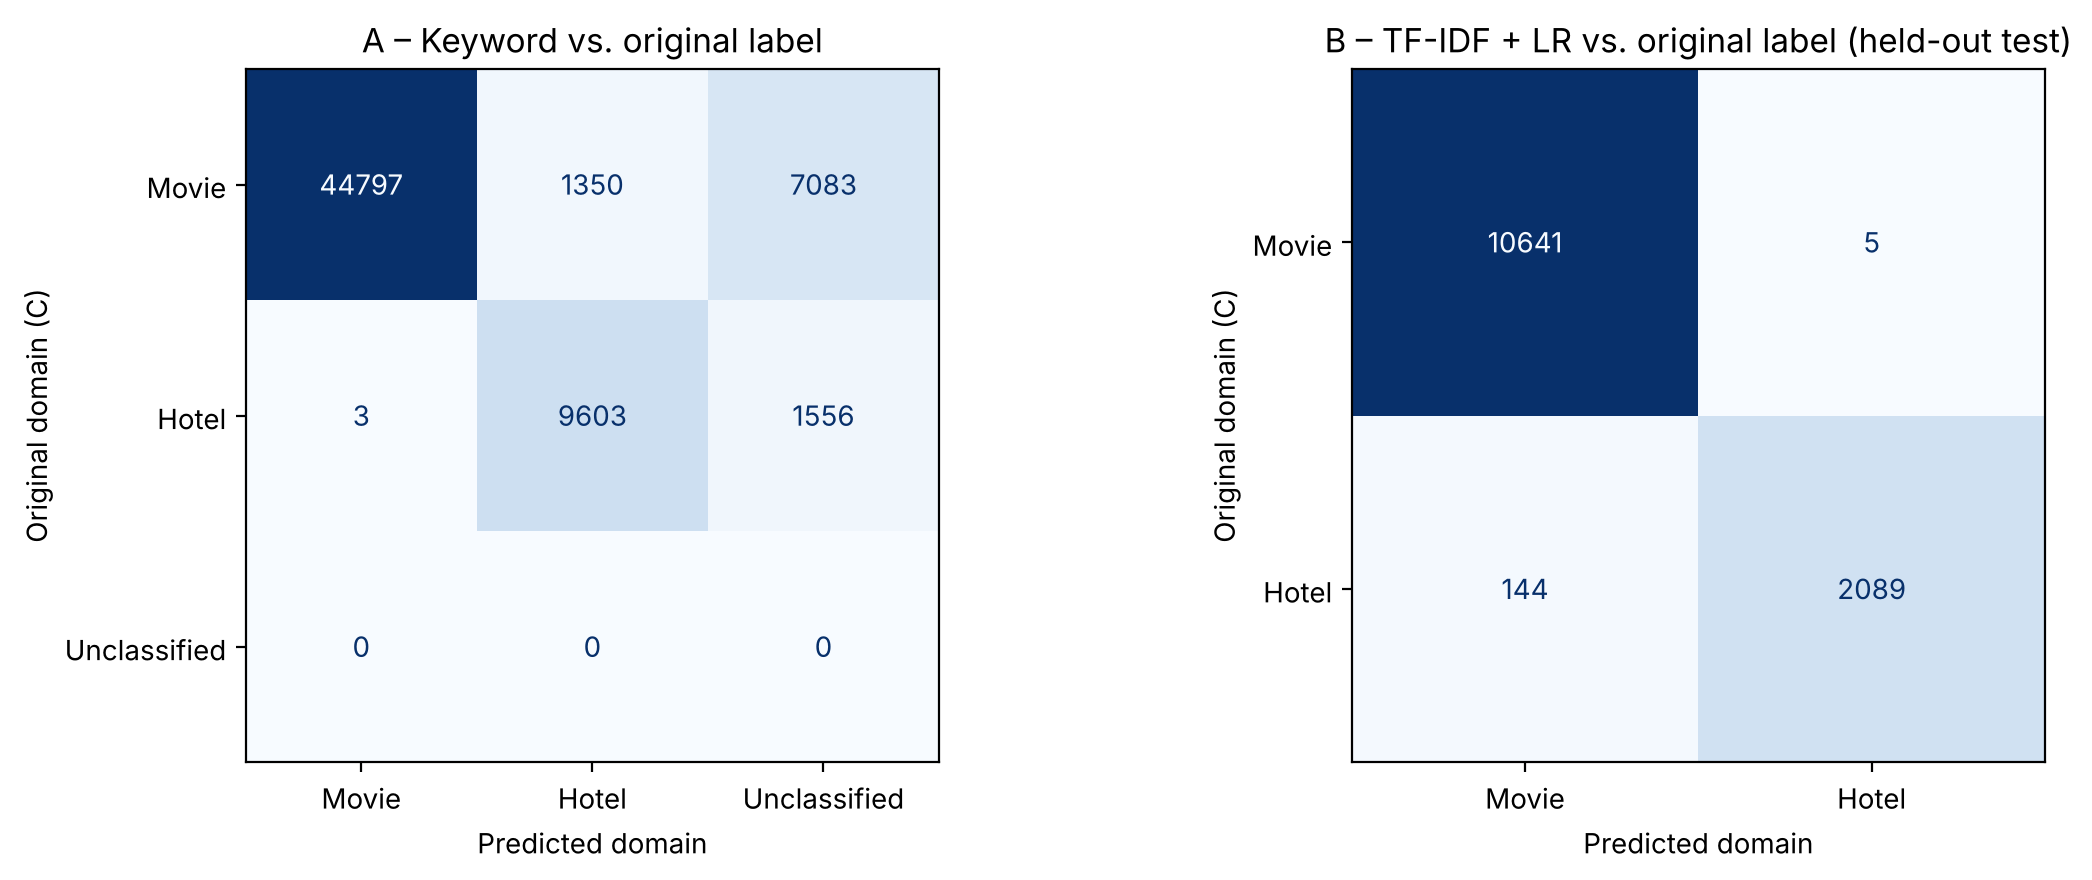

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(ref["domain_C"], ref["domain_A"], labels=DOMAINS + ["Unclassified"]),
                       display_labels=["Movie", "Hotel", "Unclassified"]).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("A – Keyword vs. original label")
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te, labels=DOMAINS),
                       display_labels=["Movie", "Hotel"]).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format="d")
axes[1].set_title("B – TF-IDF + LR vs. original label (held-out test)")
for ax in axes:
    ax.set_xlabel("Predicted domain"); ax.set_ylabel("Original domain (C)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrices.png", dpi=150)
plt.show()

## 5. Save domain assignments
The reviews without an original Type label are removed. All three domain labels are kept on the same review records, so the dataset preparation step (01 V3) can use C for the main experiments and keep A and B for the additional comparison.

In [9]:
# the reviews without an original Type label are dropped
out = ref[["text", "label", "domain_C", "domain_A", "domain_B"]]
assert len(out) == len(df) - n_unmatched and out["text"].is_unique and out.notna().all().all()
out.to_csv(f"{DATA_DIR}/humir_domain_labels_ABC.csv", index=False)
print(out.shape)
for col in ["domain_C", "domain_A", "domain_B"]:
    print(f"\n{out[col].value_counts()}")
print(f"saved: {DATA_DIR}/humir_domain_labels_ABC.csv")

(64392, 5)

domain_C
Movie Reviews    53230
Hotel Reviews    11162
Name: count, dtype: int64

domain_A
Movie Reviews    44800
Hotel Reviews    10953
Unclassified      8639
Name: count, dtype: int64

domain_B
Movie Reviews    53857
Hotel Reviews    10535
Name: count, dtype: int64
saved: ../data/humir_domain_labels_ABC.csv
